In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd
import scipy
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler, PolynomialFeatures

In [2]:
df_train = pd.read_csv(r"train\DailyDelhiClimateTrain.csv")
print(df_train.head())

df_train.dtypes

         date   meantemp   humidity  wind_speed  meanpressure
0  2013-01-01  10.000000  84.500000    0.000000   1015.666667
1  2013-01-02   7.400000  92.000000    2.980000   1017.800000
2  2013-01-03   7.166667  87.000000    4.633333   1018.666667
3  2013-01-04   8.666667  71.333333    1.233333   1017.166667
4  2013-01-05   6.000000  86.833333    3.700000   1016.500000


date                str
meantemp        float64
humidity        float64
wind_speed      float64
meanpressure    float64
dtype: object

In [3]:
df_train['date'] = pd.to_datetime(df_train['date'],  format='mixed')


print(df_train.dtypes)
print(df_train.head())
df_train.dropna(inplace=True)


date            datetime64[us]
meantemp               float64
humidity               float64
wind_speed             float64
meanpressure           float64
dtype: object
        date   meantemp   humidity  wind_speed  meanpressure
0 2013-01-01  10.000000  84.500000    0.000000   1015.666667
1 2013-01-02   7.400000  92.000000    2.980000   1017.800000
2 2013-01-03   7.166667  87.000000    4.633333   1018.666667
3 2013-01-04   8.666667  71.333333    1.233333   1017.166667
4 2013-01-05   6.000000  86.833333    3.700000   1016.500000


C:\Users\Lam\AppData\Local\Temp\ipykernel_25456\4167806323.py:16: UserWarning: AutoDateLocator was unable to pick an appropriate interval for this date range. It may be necessary to add an interval value to the AutoDateLocator's intervald dictionary. Defaulting to 6.
  plt.tight_layout()
c:\Users\Lam\anaconda3\envs\aicycle\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: AutoDateLocator was unable to pick an appropriate interval for this date range. It may be necessary to add an interval value to the AutoDateLocator's intervald dictionary. Defaulting to 6.
  fig.canvas.print_figure(bytes_io, **kw)


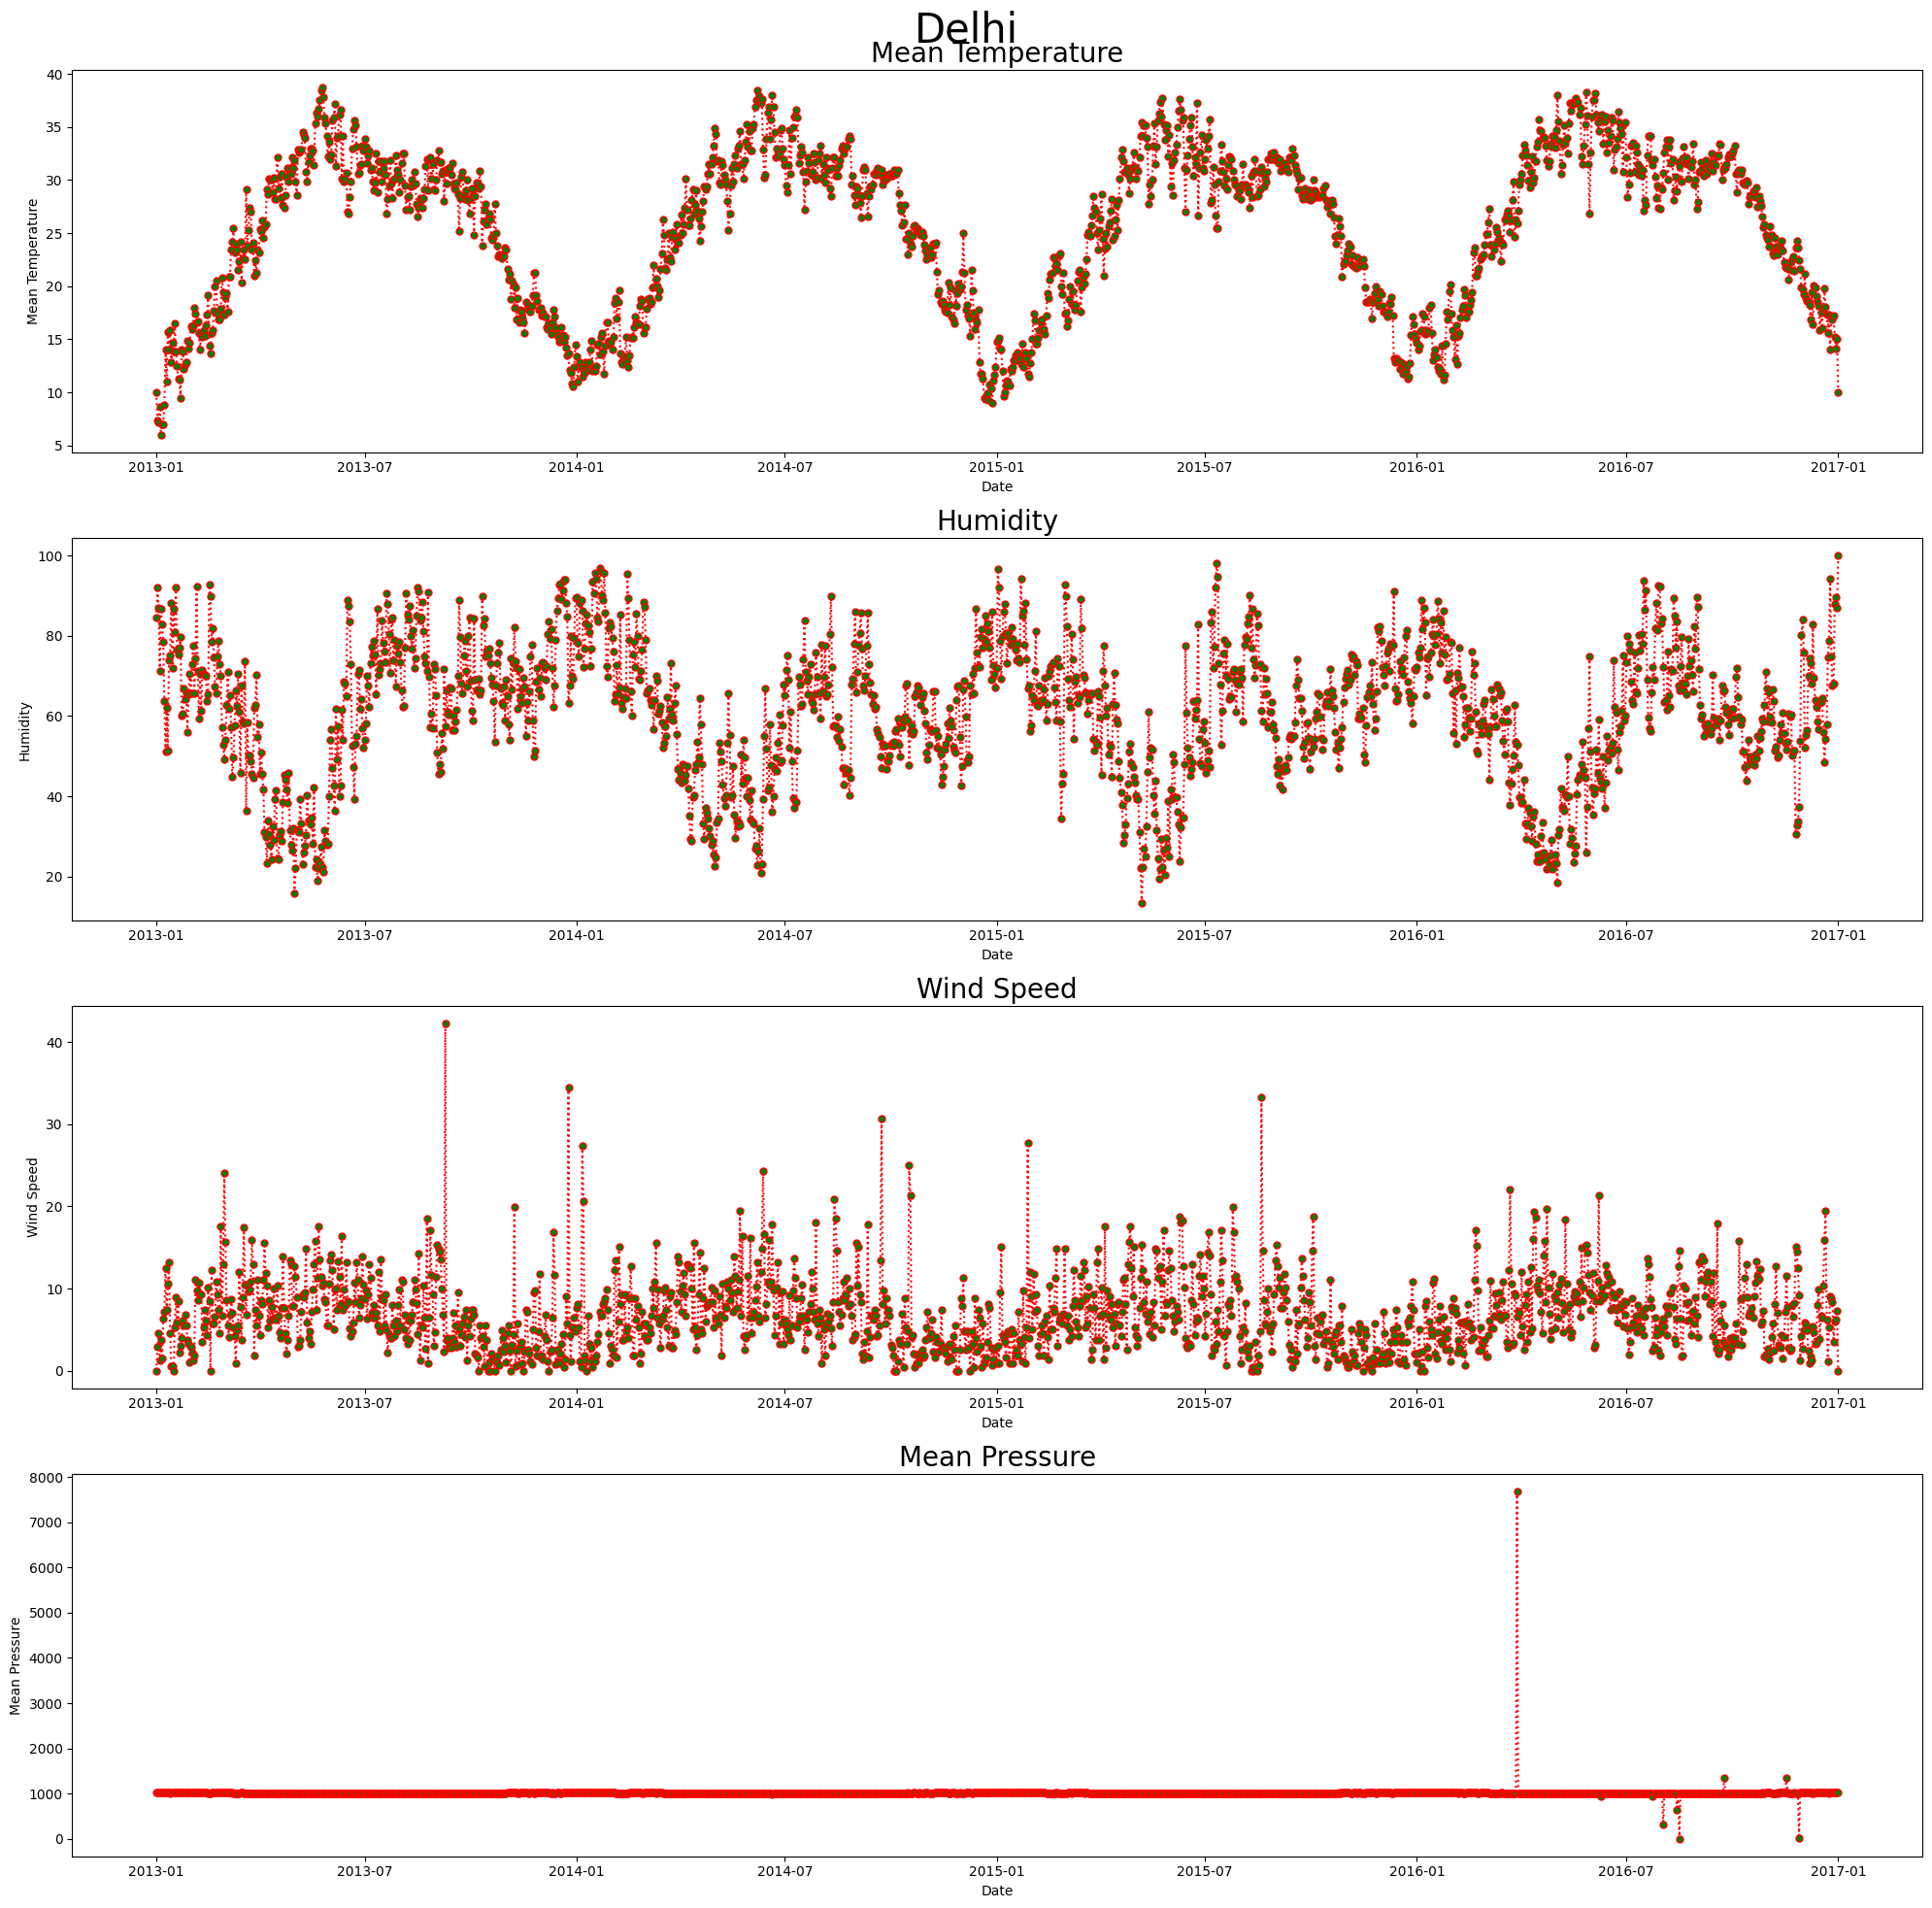

In [4]:
fig, axs = plt.subplots(4,1, figsize = (20,20))

cols = ['meantemp',	'humidity',	'wind_speed', 'meanpressure']
cols_name = ['Mean Temperature', 'Humidity', 'Wind Speed', 'Mean Pressure']

axs = axs.flatten()

for ax, col, col_name in zip(axs, cols, cols_name):
    ax.plot(df_train['date'], df_train[col], marker = 'o', c = 'r', ms = '5', mfc = 'g', ls = ":")
    ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=5))
    ax.set_ylabel(col_name)
    ax.set_xlabel('Date')
    ax.set_title(col_name, size = 20)

plt.suptitle('Delhi', size = 30)
plt.tight_layout()
plt.show()

In [5]:
def make_plot(df):

    fig, axs = plt.subplots(4,1, figsize = (20,20))

    cols = ['meantemp',	'humidity',	'wind_speed', 'meanpressure']
    cols_name = ['Mean Temperature', 'Humidity', 'Wind Speed', 'Mean Pressure']

    axs = axs.flatten()

    for ax, col, col_name in zip(axs, cols, cols_name):
        ax.plot(df['date'], df[col], marker = 'o', c = 'r', ms = '5', mfc = 'g', ls = ":")
        ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=5))
        ax.set_ylabel(col_name)
        ax.set_xlabel('Date')
        ax.set_title(col_name, size = 20)

    plt.suptitle('Delhi', size = 30)
    plt.tight_layout()
    plt.show()

In [6]:
for x in df_train.index:
    if df_train.loc[x, "meanpressure"] > 1200 or df_train.loc[x, "meanpressure"] < 900:
        df_train.drop(x, inplace=True)


[<Axes: > <Axes: > <Axes: > <Axes: >]


C:\Users\Lam\AppData\Local\Temp\ipykernel_25456\587527605.py:17: UserWarning: AutoDateLocator was unable to pick an appropriate interval for this date range. It may be necessary to add an interval value to the AutoDateLocator's intervald dictionary. Defaulting to 6.
  plt.tight_layout()
c:\Users\Lam\anaconda3\envs\aicycle\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: AutoDateLocator was unable to pick an appropriate interval for this date range. It may be necessary to add an interval value to the AutoDateLocator's intervald dictionary. Defaulting to 6.
  fig.canvas.print_figure(bytes_io, **kw)


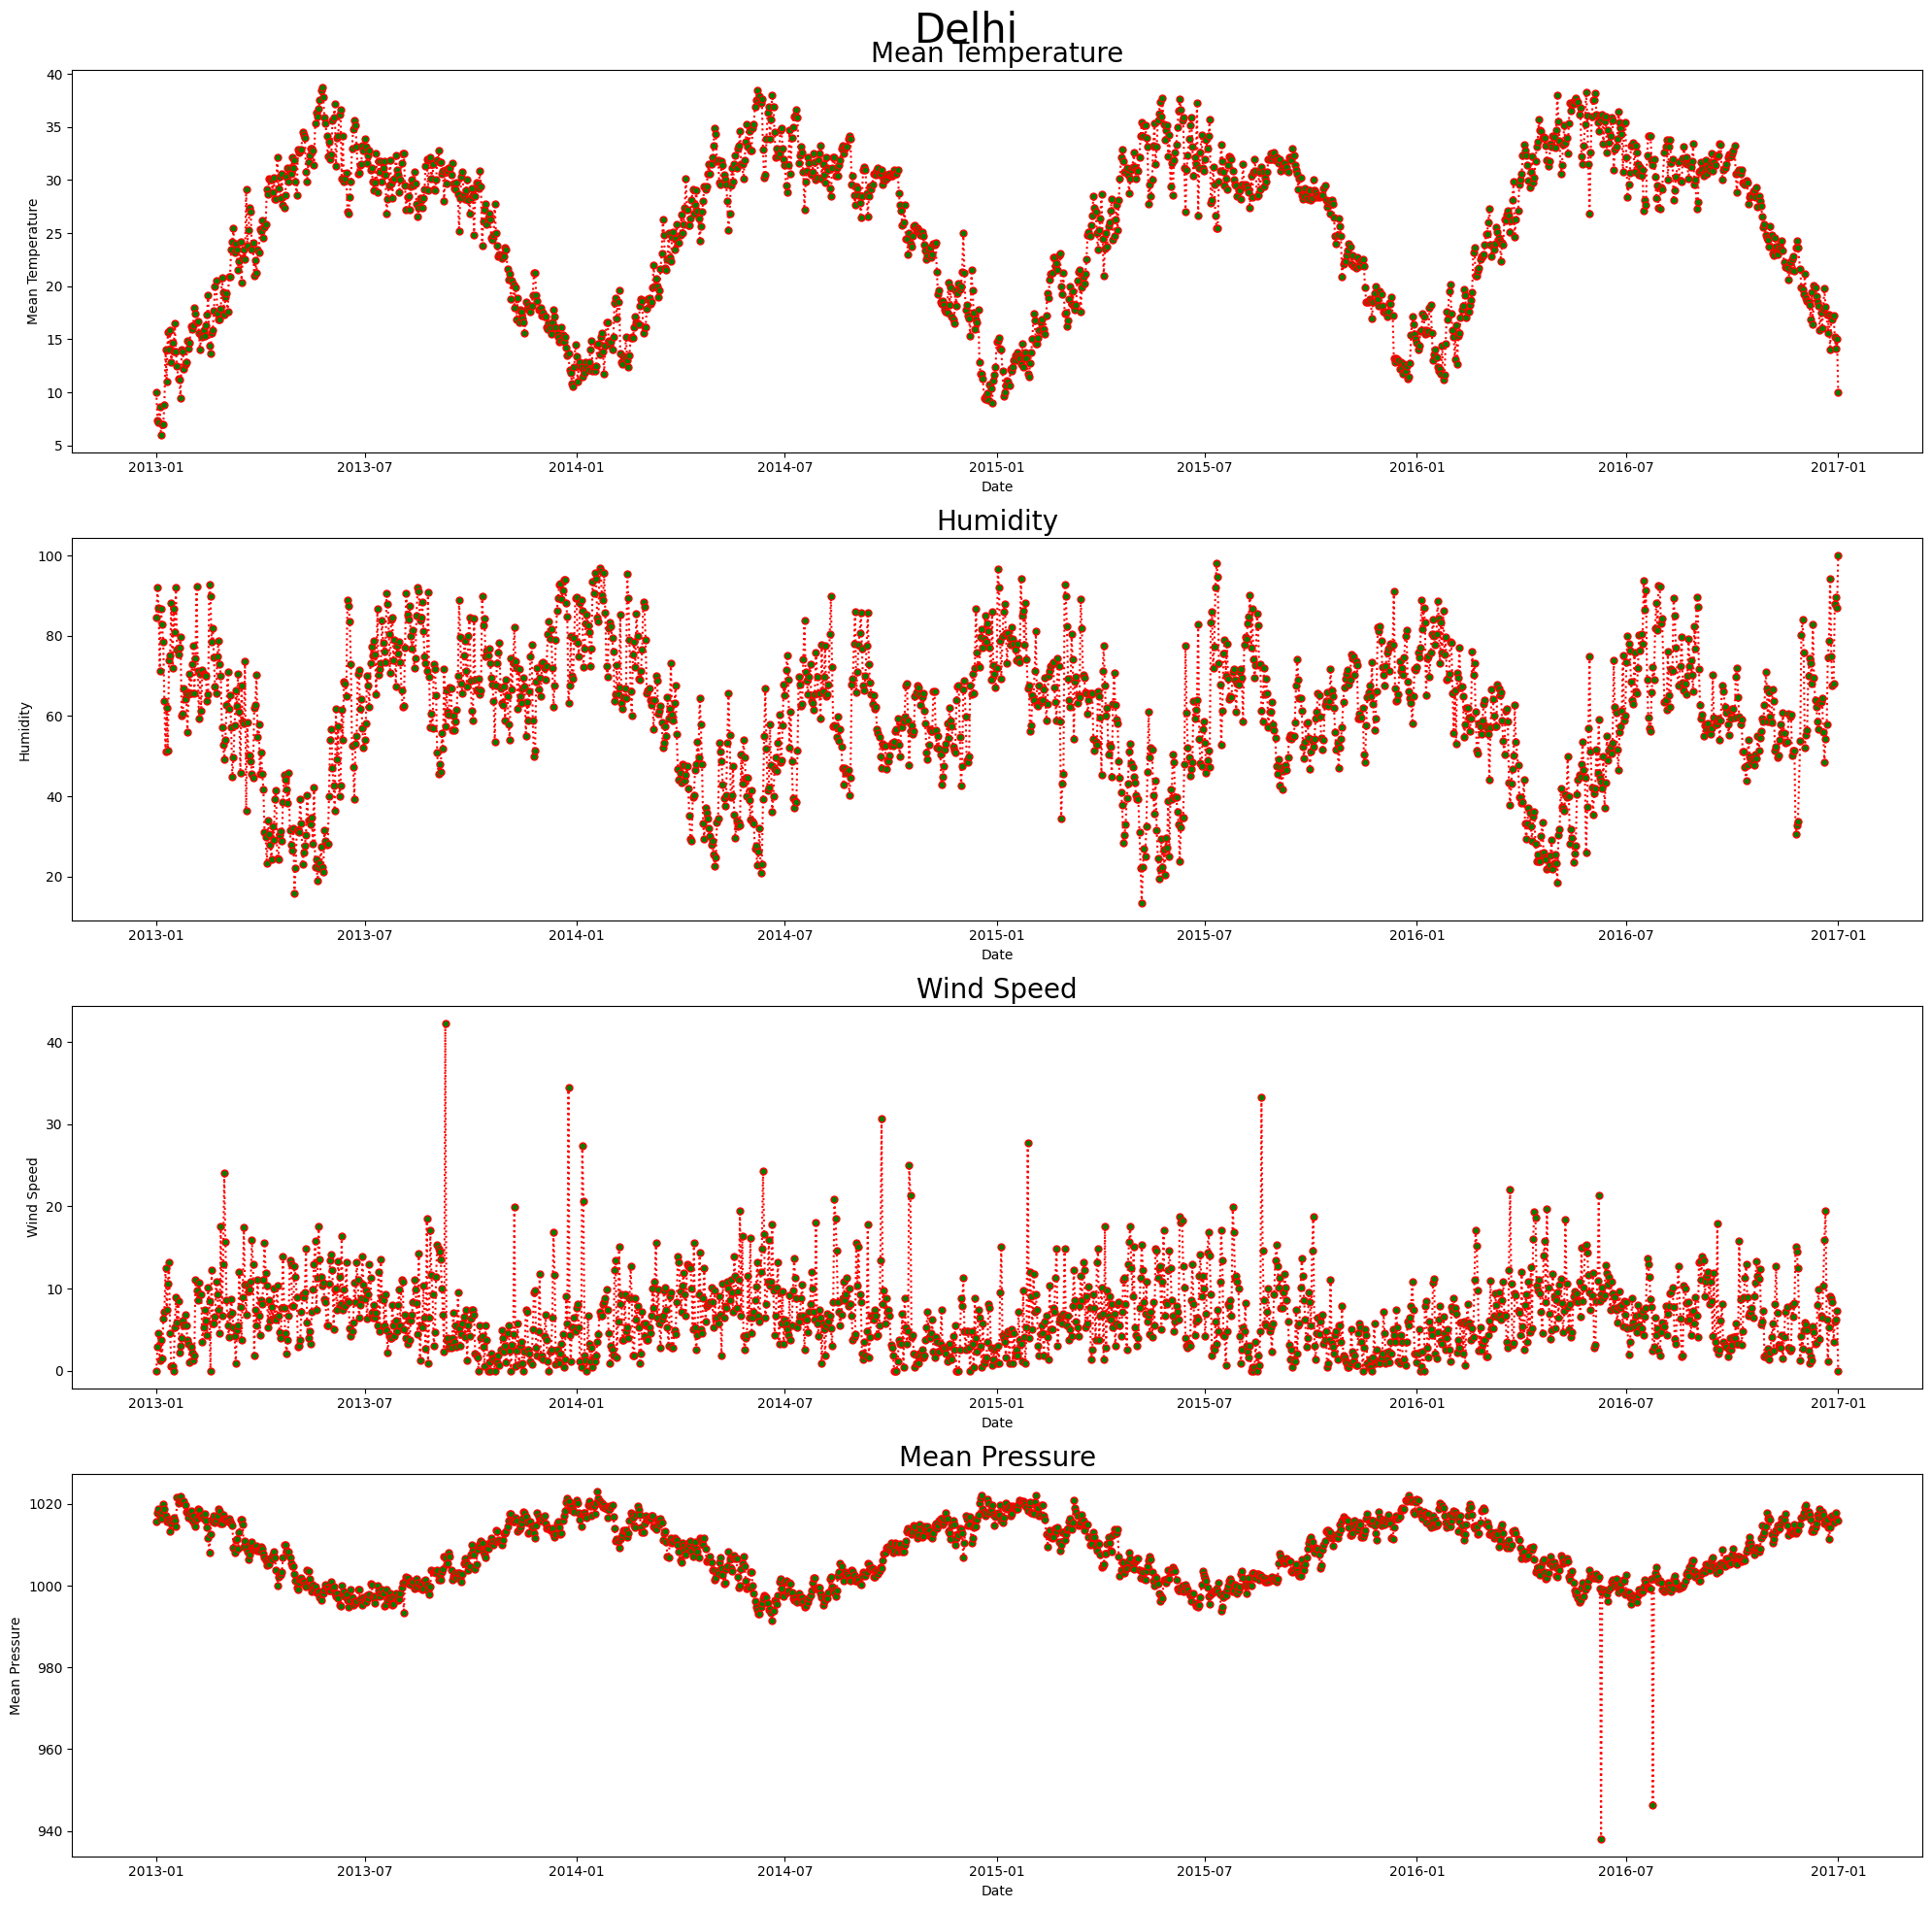

In [33]:
fig, axs = plt.subplots(4,1, figsize = (20,20))

cols = ['meantemp',	'humidity',	'wind_speed', 'meanpressure']
cols_name = ['Mean Temperature', 'Humidity', 'Wind Speed', 'Mean Pressure']

axs = axs.flatten()
print(axs)

for ax, col, col_name in zip(axs, cols, cols_name):
    ax.plot(df_train['date'], df_train[col], marker = 'o', c = 'r', ms = '5', mfc = 'g', ls = ":")
    ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=5))
    ax.set_ylabel(col_name)
    ax.set_xlabel('Date')
    ax.set_title(col_name, size = 20)

plt.suptitle('Delhi', size = 30)
plt.tight_layout()
plt.show()

In [8]:
x = np.std(df_train['meantemp'])
print(x)

var = np.var(df_train['meantemp'])
print(var)

p90 = np.percentile(df_train['meanpressure'], 90)
print(p90)

7.357187007627117
54.12820066519726
1017.7357142857143


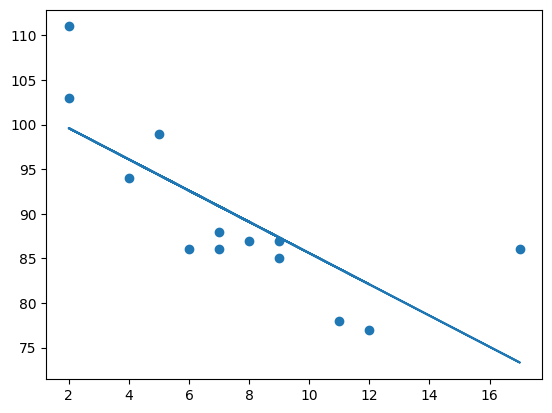

In [9]:
x = [5,7,8,7,2,17,2,9,4,11,12,9,6]
y = [99,86,87,88,111,86,103,87,94,78,77,85,86]

slope, intercept, r, p, std_err = scipy.stats.linregress(x, y)

def myfunc(x):
  return slope * x + intercept

mymodel = list(map(myfunc, x))

plt.scatter(x, y)
plt.plot(x, mymodel)
plt.show() 

C:\Users\Lam\AppData\Local\Temp\ipykernel_25456\4075737516.py:4: RankWarning: Polyfit may be poorly conditioned
  model = np.poly1d(np.polyfit(x, y, 20))


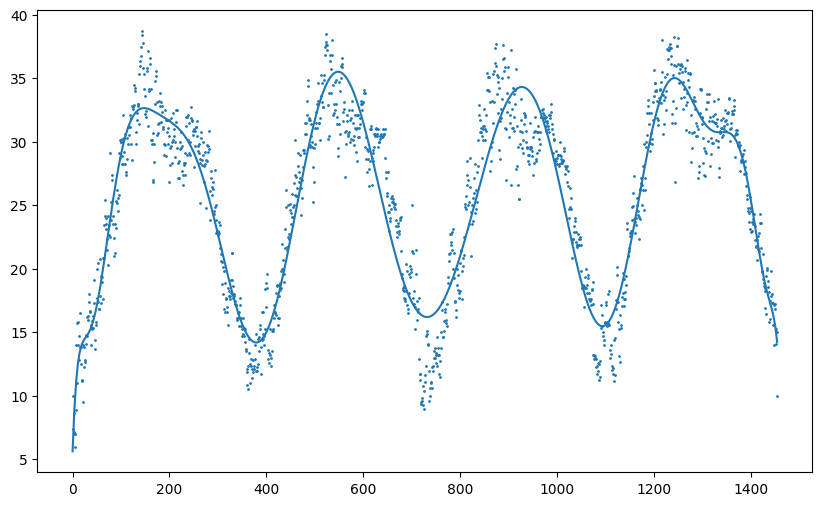

In [10]:
x = np.arange(len(df_train))
y = df_train['meantemp']

model = np.poly1d(np.polyfit(x, y, 20))

x_line = np.linspace(0, len(x)-1, 400)

plt.figure(figsize=(10,6))
plt.scatter(x, y, s = 1)
plt.plot(x_line, model(x_line))
plt.show()

In [11]:
from sklearn.metrics import r2_score

print(r2_score(y, model(x)))

0.8795351387611332


In [12]:
regr = LinearRegression()

X = pd.DataFrame({
    'date_ordinal' : df_train['date'].map(pd.Timestamp.toordinal).to_numpy(), 
    'temp' : df_train['meantemp']
    })
y = df_train['wind_speed']

regr.fit(X,y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [13]:
date = pd.to_datetime('2015-06-01').toordinal()
temp = 20

wind_speed = regr.predict([[date, temp]])
print(wind_speed)

[5.60417991]


c:\Users\Lam\anaconda3\envs\aicycle\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [14]:
X

,date_ordinal,temp
0,734869,10.000000
1,734870,7.400000
2,734871,7.166667
3,734872,8.666667
4,734873,6.000000
...,...,...
1457,736326,17.217391
1458,736327,15.238095
1459,736328,14.095238
1460,736329,15.052632


In [15]:
print(regr.coef_)

[-0.00074524  0.19596474]


In [16]:
scale = StandardScaler()
poly = PolynomialFeatures(degree=3, include_bias=False)

X2 = pd.DataFrame({
    'date_ordinal' : df_train['date'].map(pd.Timestamp.toordinal).to_numpy(), 
    'temp' : df_train['meantemp'],
    'humidity' : df_train['humidity'],
    'meanpressure' : df_train['meanpressure']
    })
y2 = df_train['wind_speed']

scaleX = scale.fit_transform(X2)
polyX = poly.fit_transform(scaleX)
print(polyX)

[[-1.72851671 -2.10488136  1.41469485 ...  1.91538719  1.2957608
   0.8765831 ]
 [-1.72614105 -2.45827729  1.86178225 ...  4.26237899  2.81525324
   1.85944301]
 [-1.72376539 -2.48999231  1.56372399 ...  3.2777069   2.80969991
   2.40851724]
 ...
 [ 1.73756706 -1.54825039  1.72268839 ...  3.68901797  2.66195897
   1.92084333]
 [ 1.73994272 -1.41812002  1.56372399 ...  2.47560961  1.60281731
   1.03773363]
 [ 1.74231838 -2.10488136  2.33867548 ...  5.46744885  2.33700463
   0.99892853]]


In [17]:
regr = LinearRegression()

regr.fit(X=scaleX, y=y2)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [18]:
regr.coef_

array([-0.1399784 , -0.56233145, -1.65195817, -1.21799253])

In [19]:
print(df_train.loc[500])

date            2014-05-16 00:00:00
meantemp                     31.125
humidity                      40.25
wind_speed                   9.4875
meanpressure                 1003.5
Name: 500, dtype: object


In [20]:
date = pd.to_datetime('2014-05-16').toordinal()
temp = 31.125
humidity = 40.25
pressure = 1003.5

In [21]:
scaled = scale.transform([[date,temp,humidity,pressure]])
print(scaled)

[[-0.54068814  0.76646064 -1.22312079 -0.59788131]]


c:\Users\Lam\anaconda3\envs\aicycle\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [22]:
predict = regr.predict(scaled)
print(predict)

[9.1870054]


In [23]:
predict_array = regr.predict(scaleX)
predict_array

array([4.71647548, 3.84422044, 4.21919515, ..., 3.06110919, 3.53113526,
       2.65236895], shape=(1455,))

In [24]:
r2_score_train = r2_score(df_train['wind_speed'], predict_array)
print(r2_score_train)

0.17269697237502135


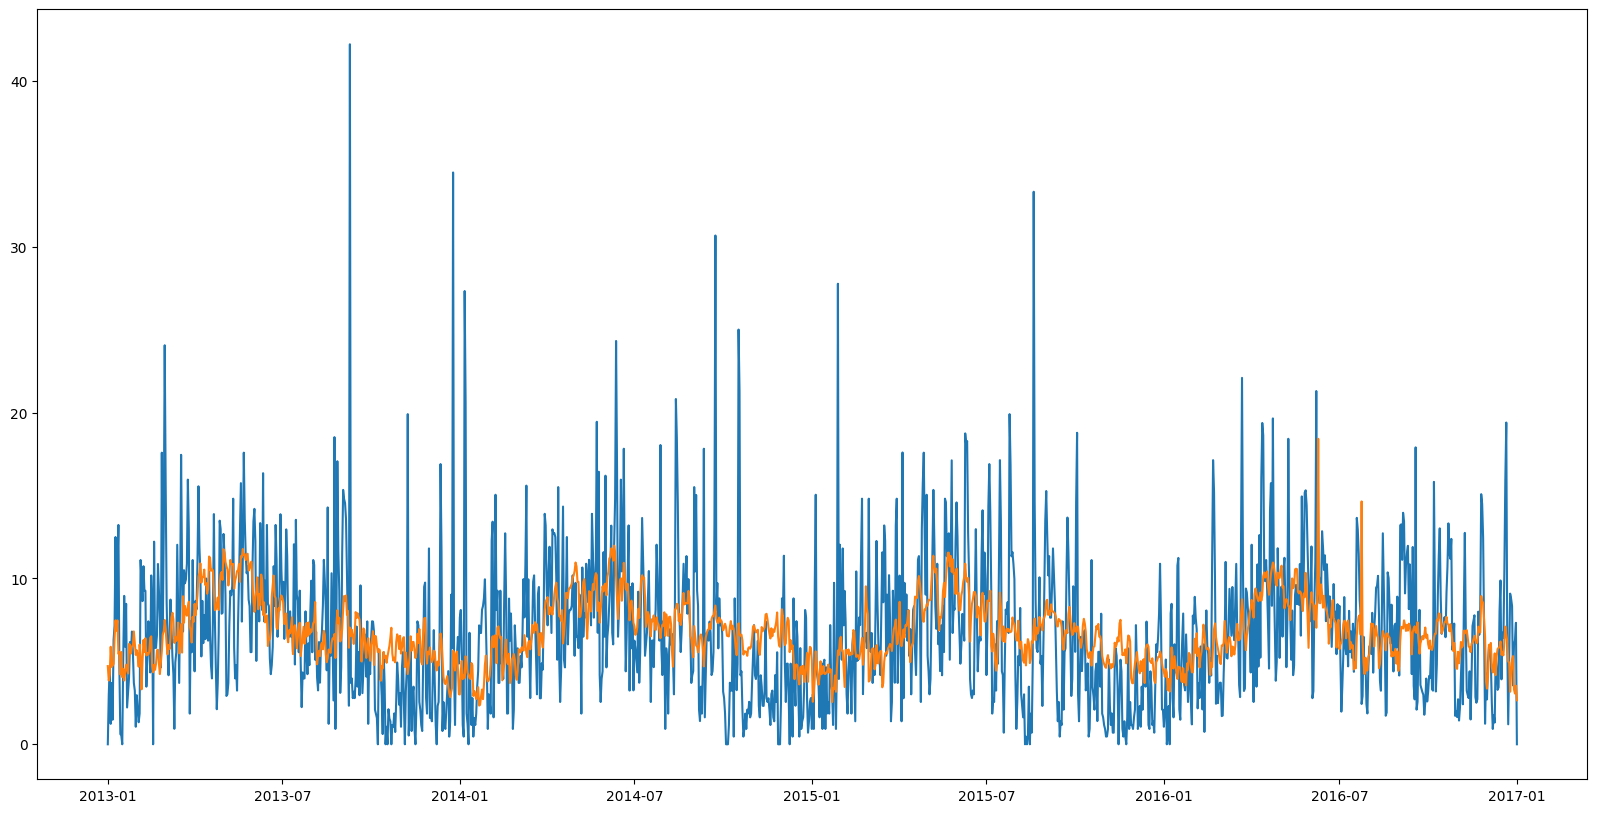

In [25]:
plt.figure(figsize=(20,10))
plt.plot(df_train['date'], df_train['wind_speed'])
plt.plot(df_train['date'], predict_array)
plt.show()

In [26]:
df_test = pd.read_csv(r'train\DailyDelhiClimateTest.csv')

"""AssertionError
X_test = pd.DataFrame({
    'date_ordinal' : df_test['date'].map(pd.Timestamp.toordinal).to_numpy(), 
    'temp' : df_test['meantemp'],
    'humidity' : df_test['humidity'],
    })
"""
df_test

,date,meantemp,humidity,wind_speed,meanpressure
0,2017-01-01,15.913043,85.869565,2.743478,59.000000
1,2017-01-02,18.500000,77.222222,2.894444,1018.277778
2,2017-01-03,17.111111,81.888889,4.016667,1018.333333
3,2017-01-04,18.700000,70.050000,4.545000,1015.700000
4,2017-01-05,18.388889,74.944444,3.300000,1014.333333
...,...,...,...,...,...
109,2017-04-20,34.500000,27.500000,5.562500,998.625000
110,2017-04-21,34.250000,39.375000,6.962500,999.875000
111,2017-04-22,32.900000,40.900000,8.890000,1001.600000
112,2017-04-23,32.875000,27.500000,9.962500,1002.125000


In [27]:
df_test['date'] = pd.to_datetime(df_test['date'], format="mixed")
df_test

,date,meantemp,humidity,wind_speed,meanpressure
0,2017-01-01,15.913043,85.869565,2.743478,59.000000
1,2017-01-02,18.500000,77.222222,2.894444,1018.277778
2,2017-01-03,17.111111,81.888889,4.016667,1018.333333
3,2017-01-04,18.700000,70.050000,4.545000,1015.700000
4,2017-01-05,18.388889,74.944444,3.300000,1014.333333
...,...,...,...,...,...
109,2017-04-20,34.500000,27.500000,5.562500,998.625000
110,2017-04-21,34.250000,39.375000,6.962500,999.875000
111,2017-04-22,32.900000,40.900000,8.890000,1001.600000
112,2017-04-23,32.875000,27.500000,9.962500,1002.125000


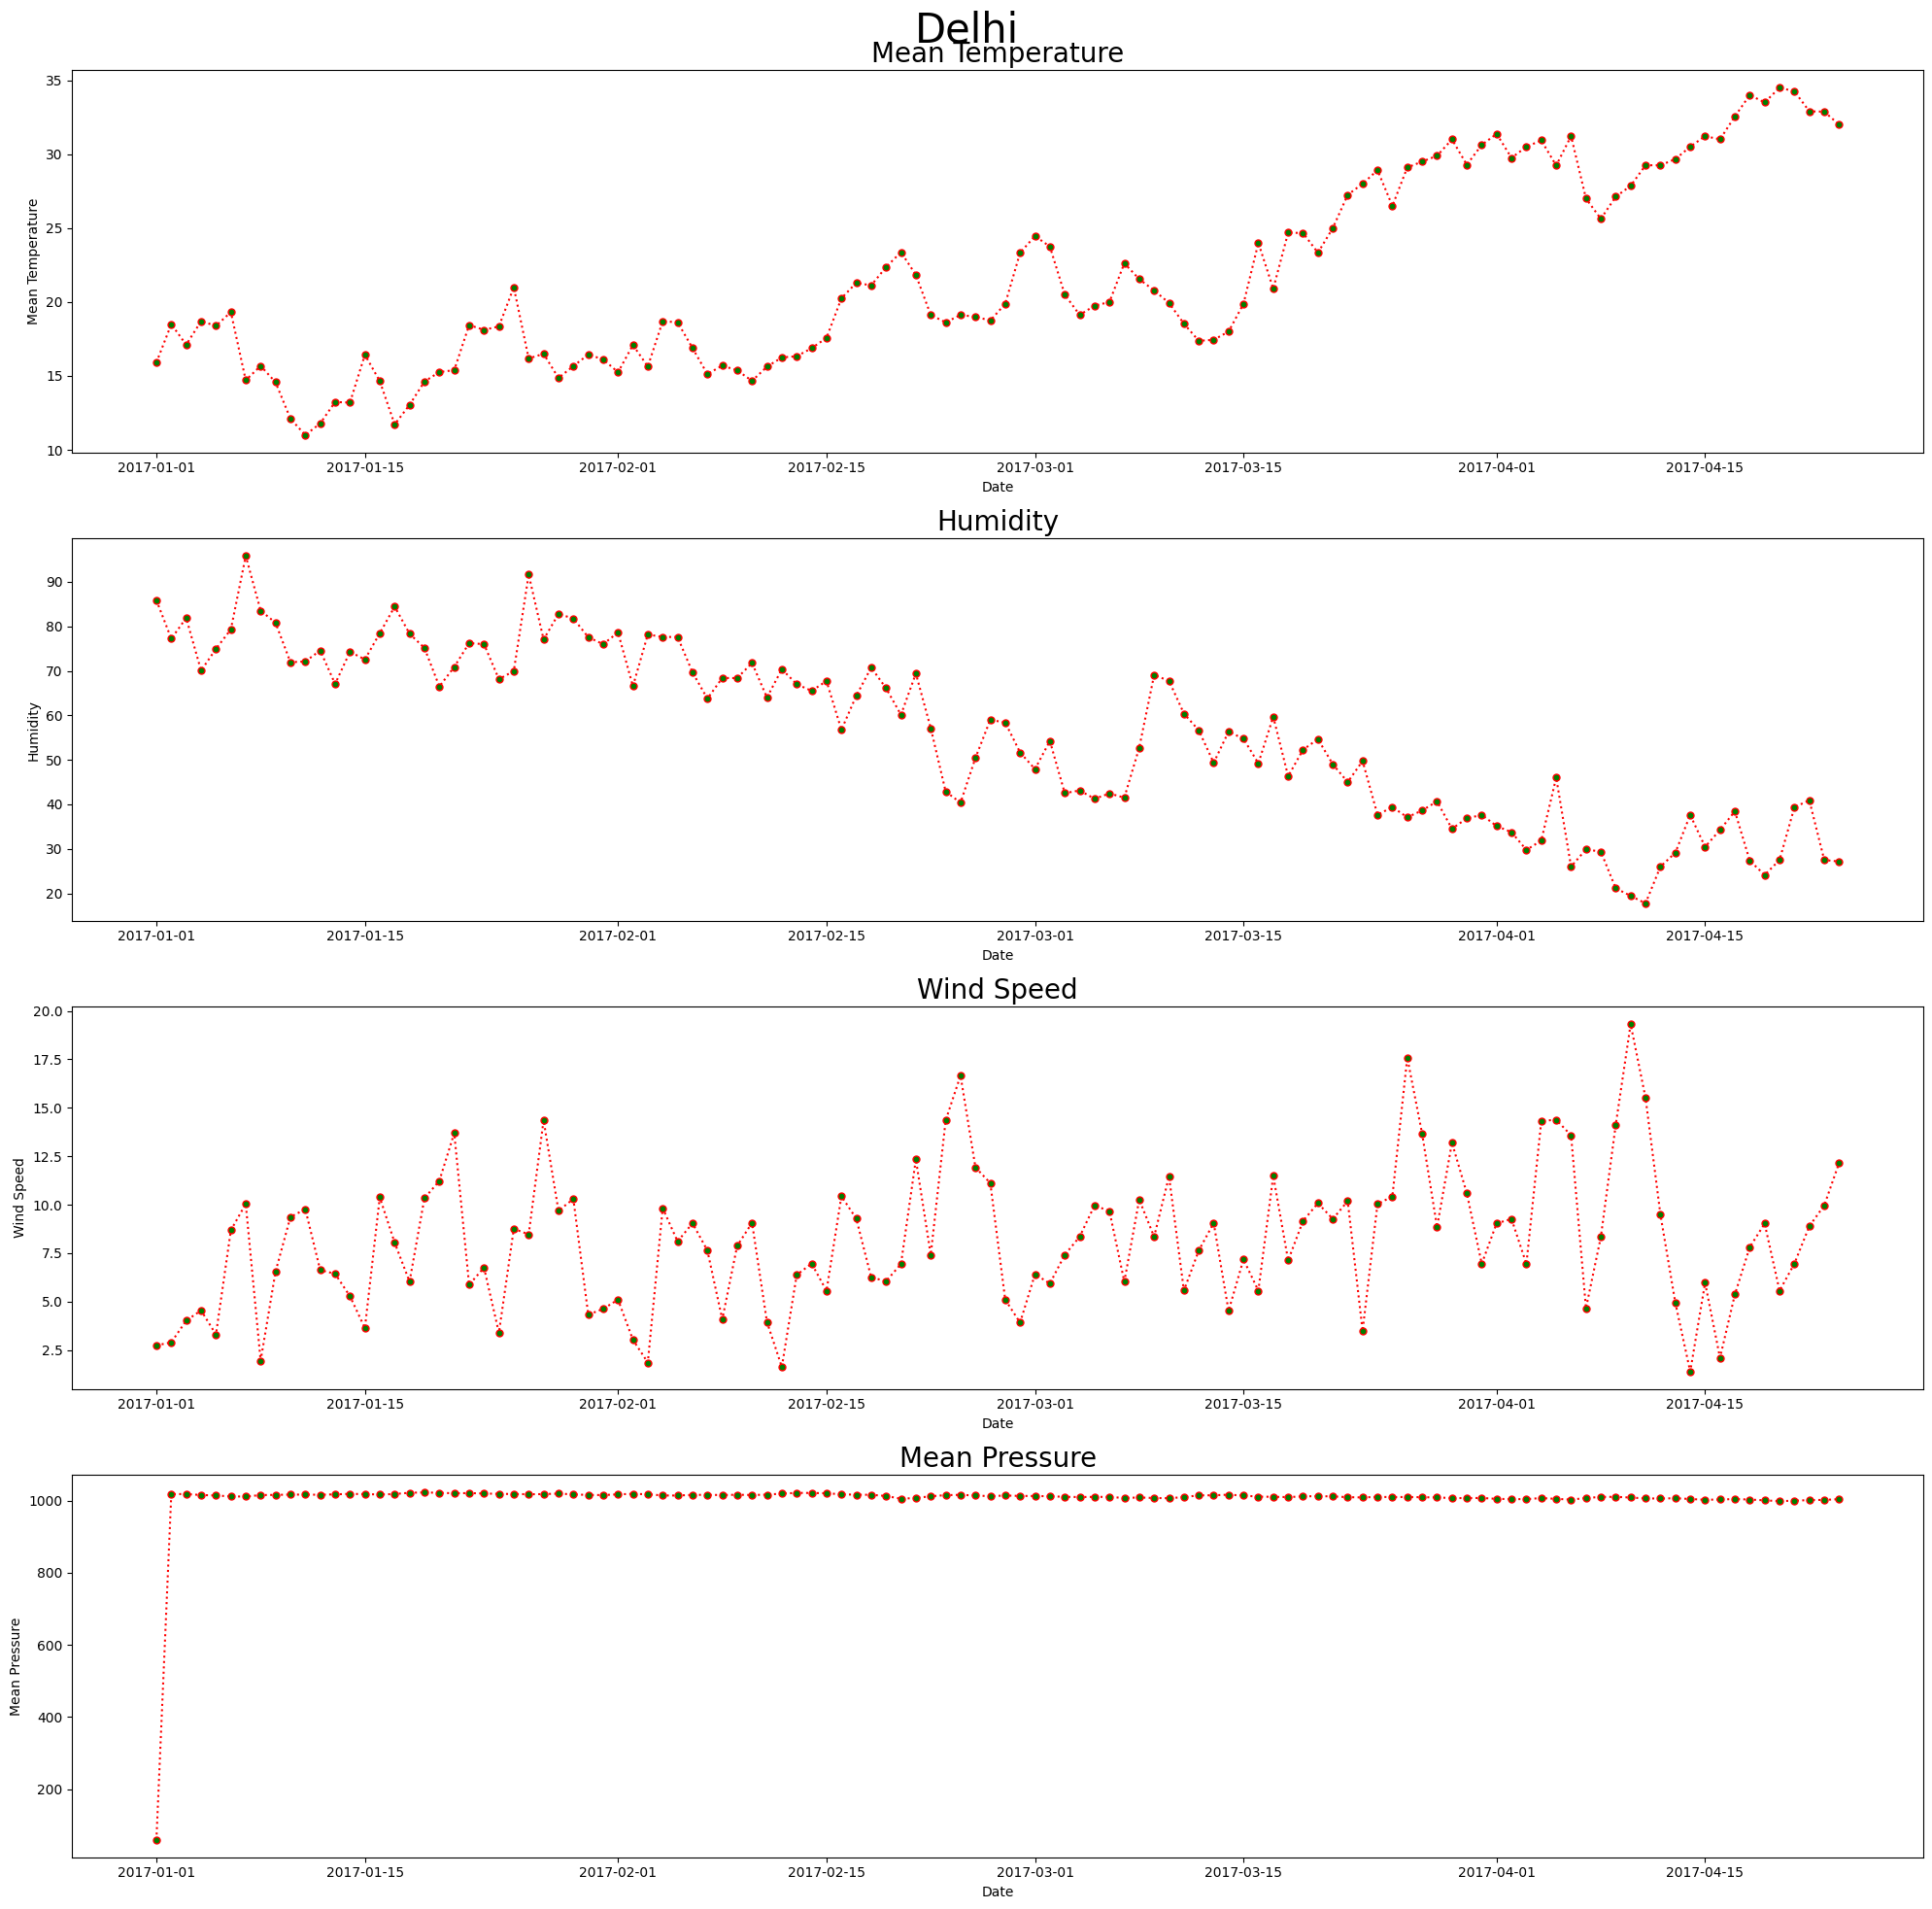

In [28]:
make_plot(df_test)

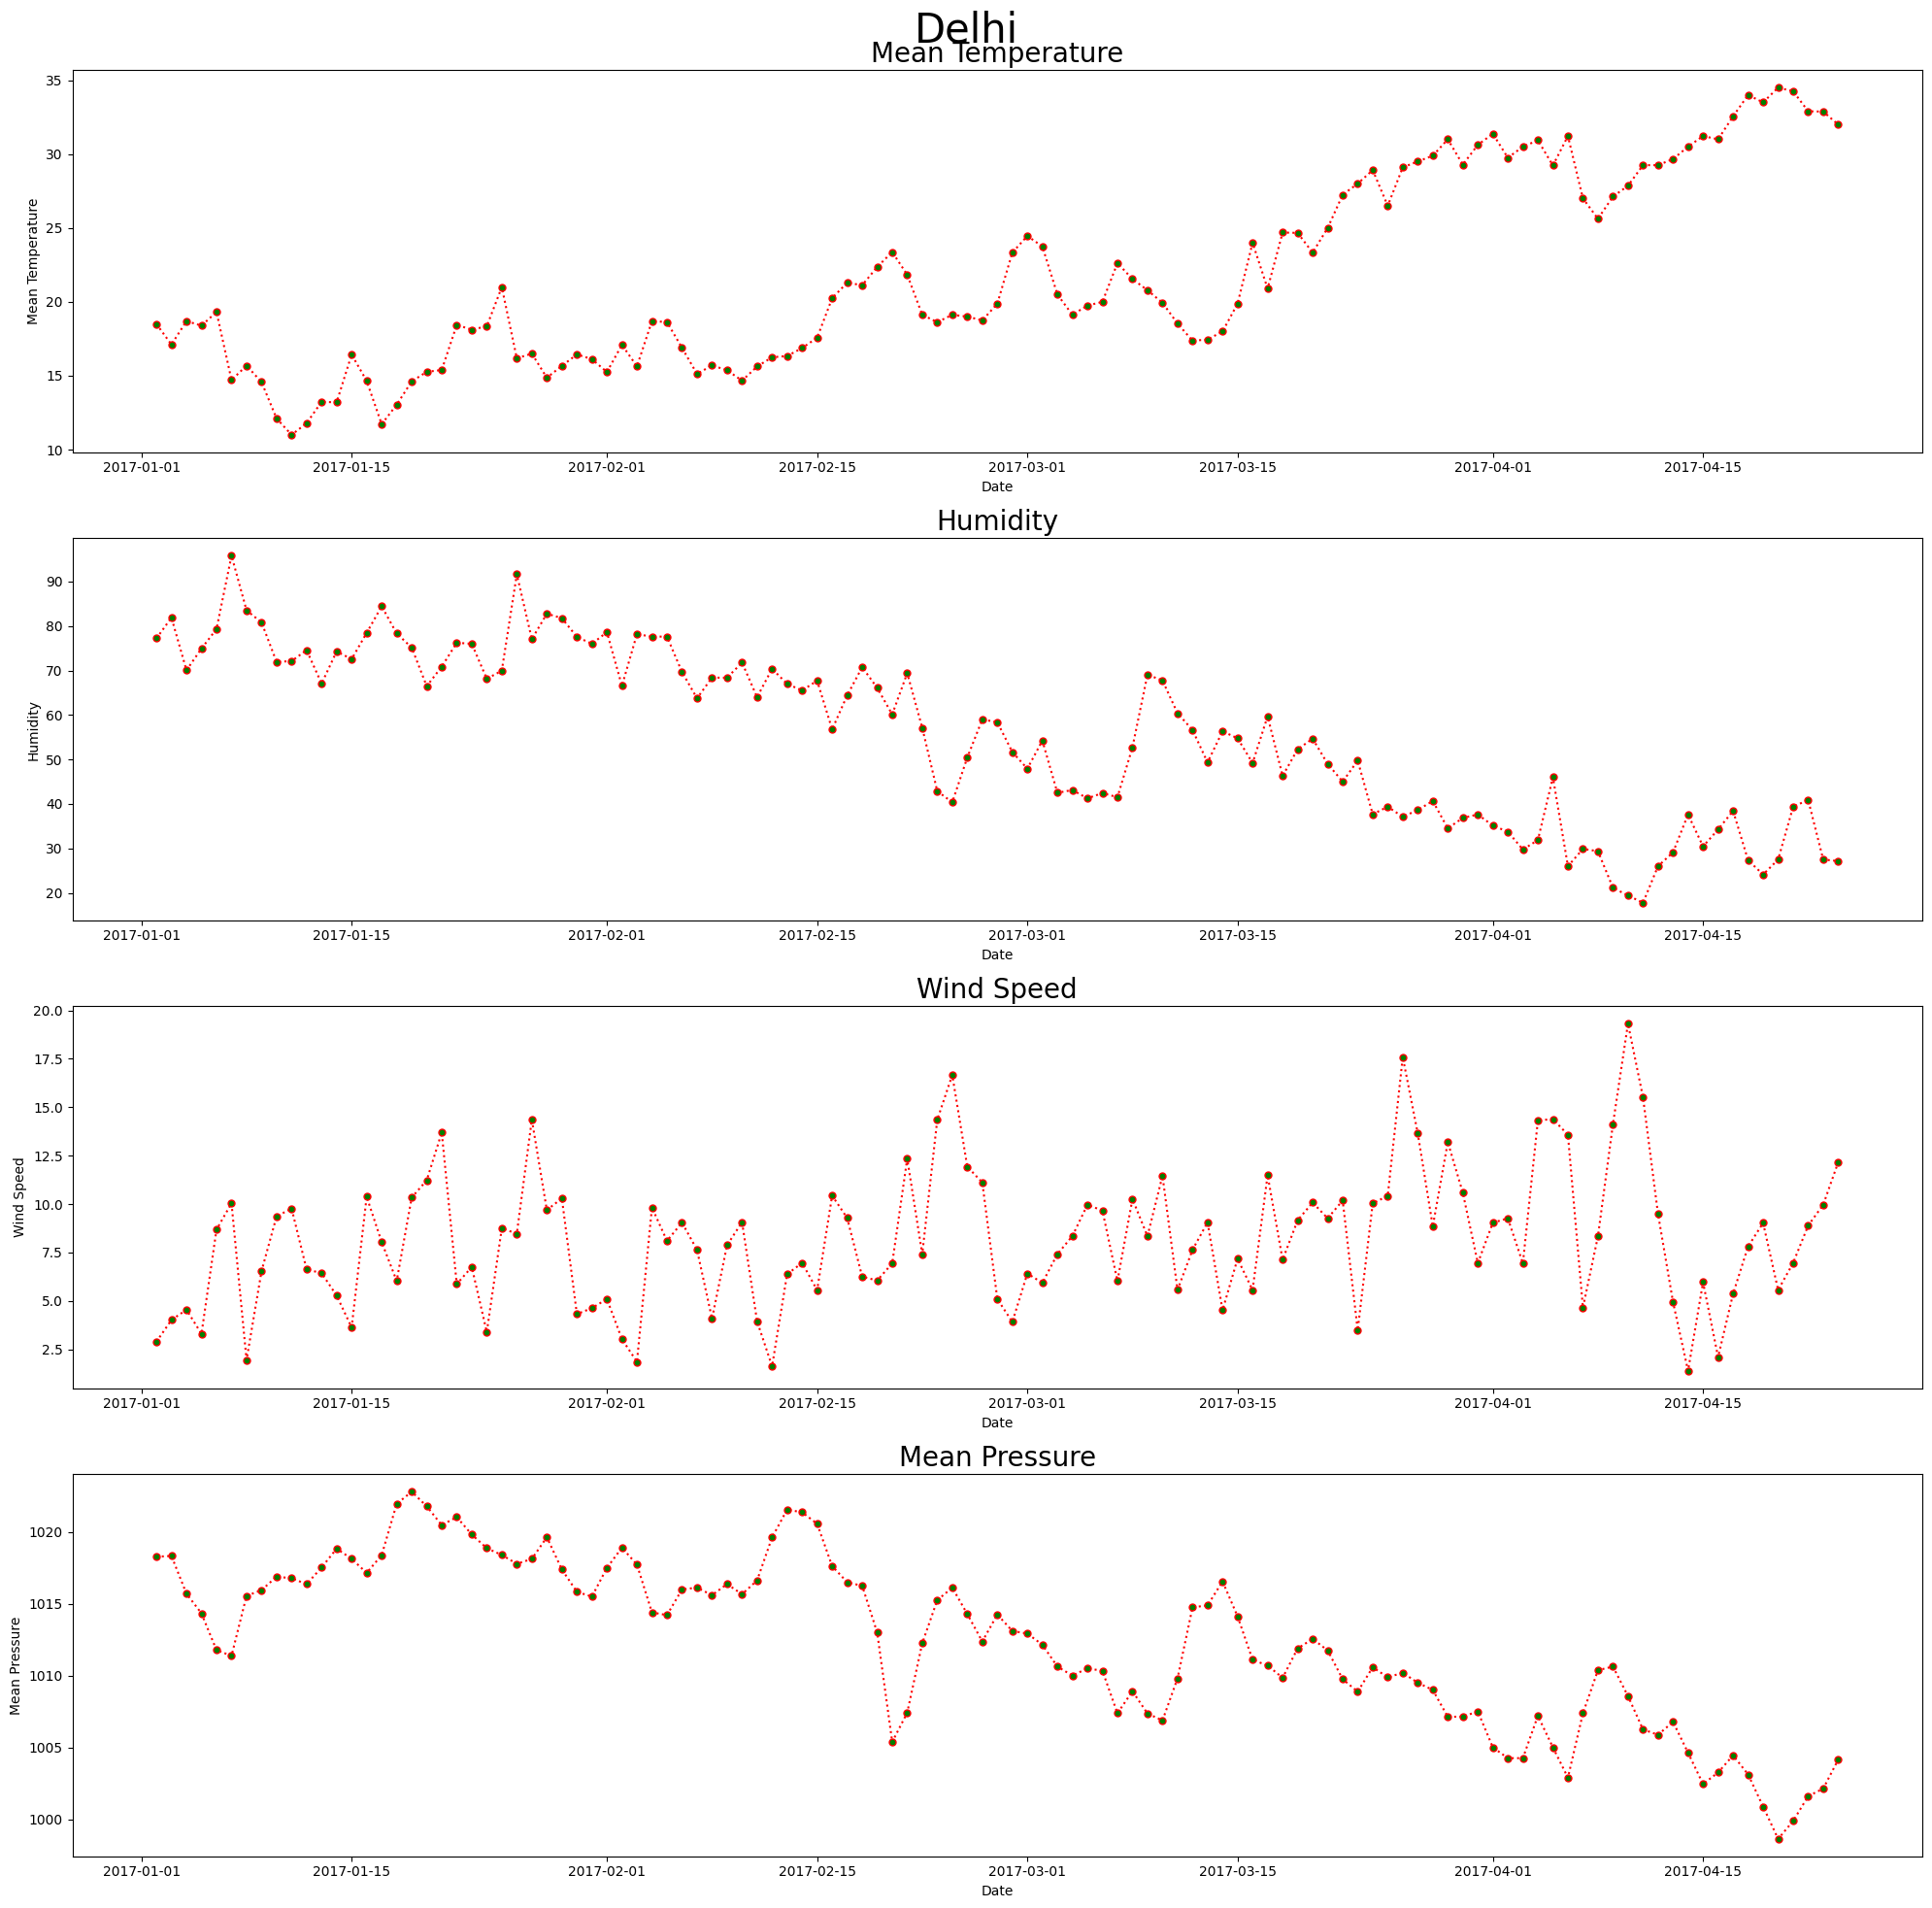

In [29]:
for i in df_test.index:
    if df_test.loc[i, 'meanpressure'] < 900:
        df_test.drop(i, inplace=True)

make_plot(df_test)

In [30]:
X_test = pd.DataFrame({
    'date_ordinal' : df_test['date'].map(pd.Timestamp.toordinal).to_numpy(), 
    'temp' : df_test['meantemp'],
    'humidity' : df_test['humidity'],
    'meanpressure' : df_test['meanpressure'],
    })
X_test

,date_ordinal,temp,humidity,meanpressure
1,736331,18.500000,77.222222,1018.277778
2,736332,17.111111,81.888889,1018.333333
3,736333,18.700000,70.050000,1015.700000
4,736334,18.388889,74.944444,1014.333333
5,736335,19.318182,79.318182,1011.772727
...,...,...,...,...
109,736439,34.500000,27.500000,998.625000
110,736440,34.250000,39.375000,999.875000
111,736441,32.900000,40.900000,1001.600000
112,736442,32.875000,27.500000,1002.125000


In [31]:
X_test_scaled = scale.transform(X_test)
y_test = regr.predict(X_test_scaled)
y_true = df_test['wind_speed']

r2_score_test = r2_score(y_true, y_test)
print(r2_score_test)

-0.18950056504849977


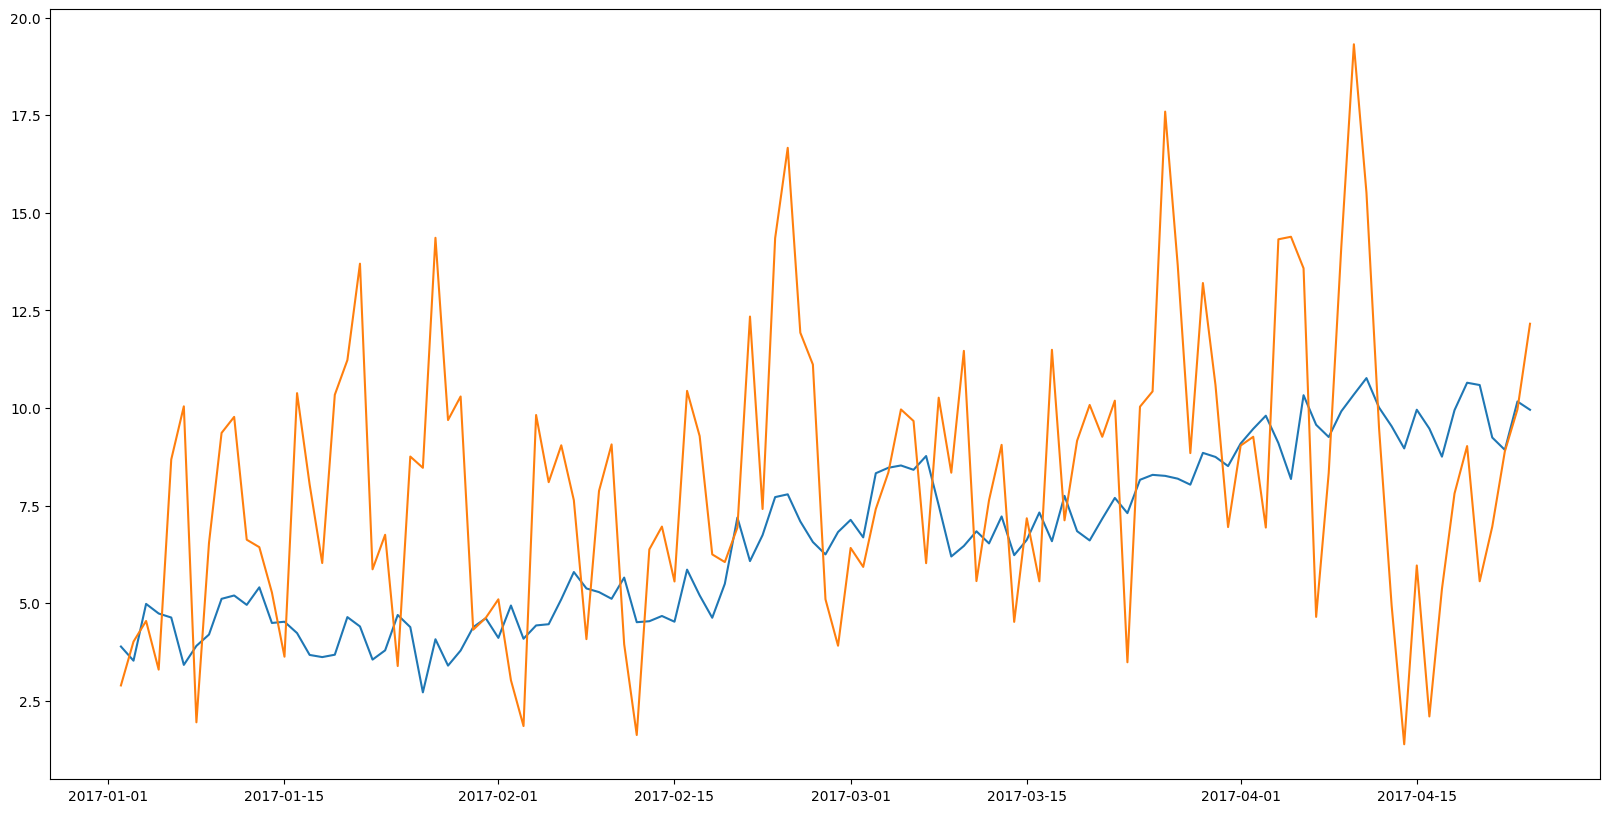

In [32]:
plt.figure(figsize=(20,10))
plt.plot(df_test['date'], y_test)
plt.plot(df_test['date'], y_true)
plt.show()